<a href="https://colab.research.google.com/github/Jirehcode/Codveda-ML-tasks/blob/main/task-4-classifer-comparison/Classifier_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_curve, auc)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import label_binarize

# Mount drive unto google.colab

from google.colab import drive
import os
if not os.path.exists('/content/drive'):
   drive.mount('/content/drive')
   print('Google Drive is mounted')
else:
   print('Google Drive is already mounted')


Google Drive is already mounted


In [ ]:
#Loading Iris csv file onto Pandas dataframe

df = pd.read_csv("/content/drive/MyDrive/Codveda Data science Task List/1) iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Decision Tree Classifier:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



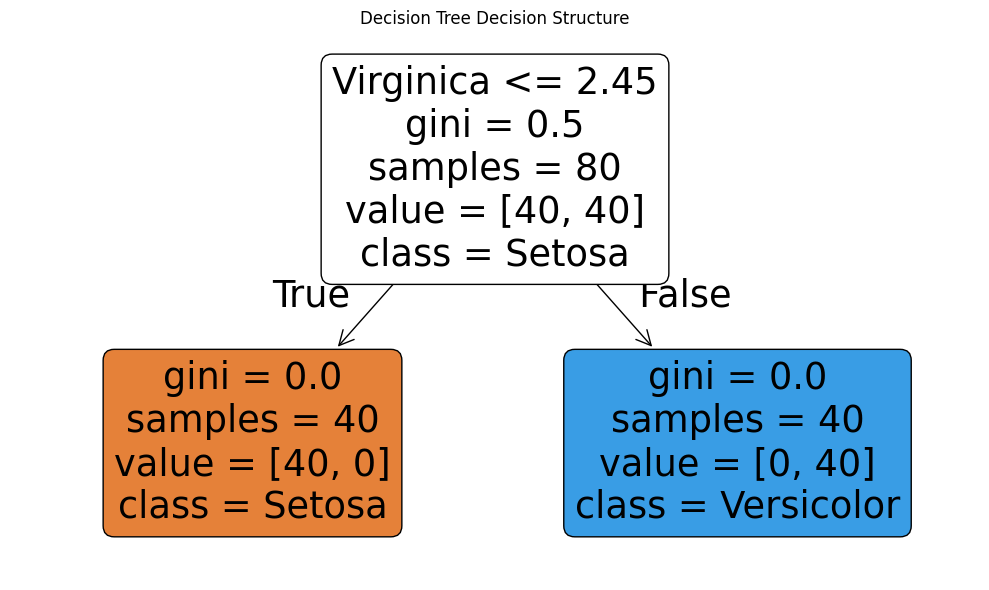

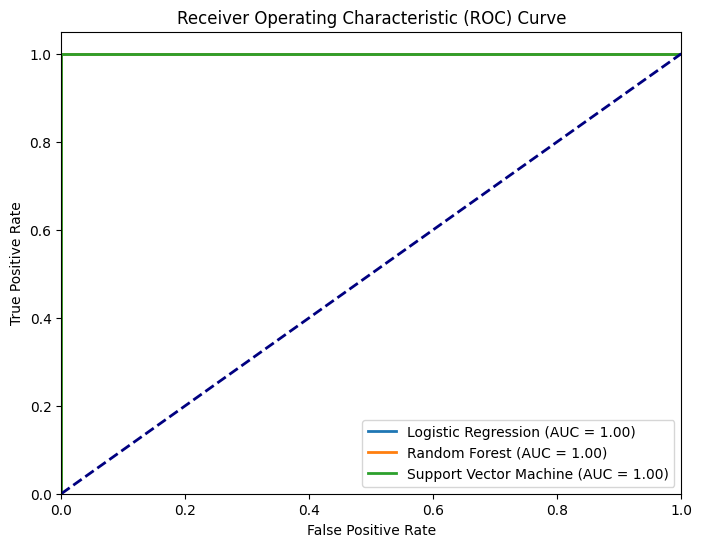


Model Comparison:
                 Model  Accuracy  Precision  Recall  F1 Score
   Logistic Regression       1.0        1.0     1.0       1.0
         Random Forest       1.0        1.0     1.0       1.0
Support Vector Machine       1.0        1.0     1.0       1.0


In [ ]:
# Filter for binary classification (Setosa vs Versicolor) for ROC visual clarity

X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
y = df['species']
y = y.map({'setosa': 0, 'versicolor': 1, 'virginica': 2})

binary_mask = y < 2
X_binary = X[binary_mask]
y_binary = y[binary_mask]

# Train-Test Split (80/20)

X_train, X_test, y_train, y_test = train_test_split(X_binary, y_binary, test_size=0.2, random_state=42, stratify = y_binary)

# Feature Scaling (Crucial for Logistic Regression & SVM)

feature_names = ['Satosa', 'Versicolor', 'Virginica']
target_names = ['Setosa', 'Versicolor', 'Virginica']
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Decision Tree Classifier

dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)
print("Decision Tree Classifier:")
print(classification_report(y_test, dt_preds, target_names=target_names[:2]))

# Visualize Decision Tree

plt.figure(figsize=(10, 6))
plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=target_names[:2],
    filled=True,
    rounded=True,
)
plt.title("Decision Tree Decision Structure")
plt.tight_layout()
plt.show()

# Logistic Regression & Comparison

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(probability=True, kernel='rbf', random_state=42)
}

results = []
plt.figure(figsize=(8, 6))

for name, model in models.items():
  if name in ["Logistic Regression", "Support Vector Machine"]:
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
  else:
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

  # Evaluate Metrics

  accuracy = accuracy_score(y_test, preds)
  precision = precision_score(y_test, preds, zero_division=0)
  recall = recall_score(y_test, preds, zero_division=0)
  f1 = f1_score(y_test, preds, zero_division=0)

  # Store Results

  results.append({
      "Model": name,
      "Accuracy": accuracy,
      "Precision": precision,
      "Recall": recall,
      "F1 Score": f1
      })

  # Calculate ROC Curve & AUC

  fpr, tpr, thresholds = roc_curve(y_test, probs)
  roc_auc = auc(fpr, tpr)
  plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.2f})")

# Plot ROC Curves

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# Display Model Comparison Table

results_df = pd.DataFrame(results)
print("\nModel Comparison:")
print(results_df.to_string(index=False))